# Scholte waves: water can mimic seabed change

**Question.** If a coastal instrument records changing dispersion, how much of the apparent seabed change could come from the overlying water column?

Use a homogeneous volcanic-rock halfspace beneath **500 m of acoustic water**. This is a synthetic coastal benchmark, not Cook Inlet bathymetry. A finite pressure-release water column produces a fluid–solid-coupled Rayleigh/Scholte branch whose speed can exceed the water sound speed at some frequencies; it should not automatically be interpreted as the deep-water Scholte limit.

We compare the numerical branch with an independently evaluated finite-water secular equation, then invert a water-level-only perturbation with different water priors. The water block enforces zero pressure at its free surface, zero solid shear traction at the seabed, and continuity of normal displacement and normal traction.


In [1]:
import sys
from pathlib import Path

# Run from the repository root or its tutorials/ directory.
root = Path.cwd().resolve()
if root.name == "tutorials":
    root = root.parent
if not (root / "src" / "gesc").is_dir():
    raise RuntimeError("Run this notebook from the gesc-python checkout.")
sys.path.insert(0, str(root))
sys.path.insert(0, str(root / "src"))
import matplotlib.pyplot as plt
import numpy as np

from gesc import solve_modes
from gesc.inversion import LinearInverseRequest, infer_time_lapse
from gesc.sensitivity import linearize_phase, perturb_model
from tutorials.plotting import emit_metrics, model_table, style
from tutorials.scenarios import correlated_covariance, phase_observation

style()
np.set_printoptions(precision=5, suppress=True)
%matplotlib inline

Depth (m),Vp (m/s),Vs (m/s),Density (kg/m³)
0–∞,4000.0,2000.0,2500.0


Water: {'depth_m': 500.0, 'sound_speed_m_s': 1500.0, 'density_kg_m3': 1000.0, 'surface_boundary': 'pressure_release'}


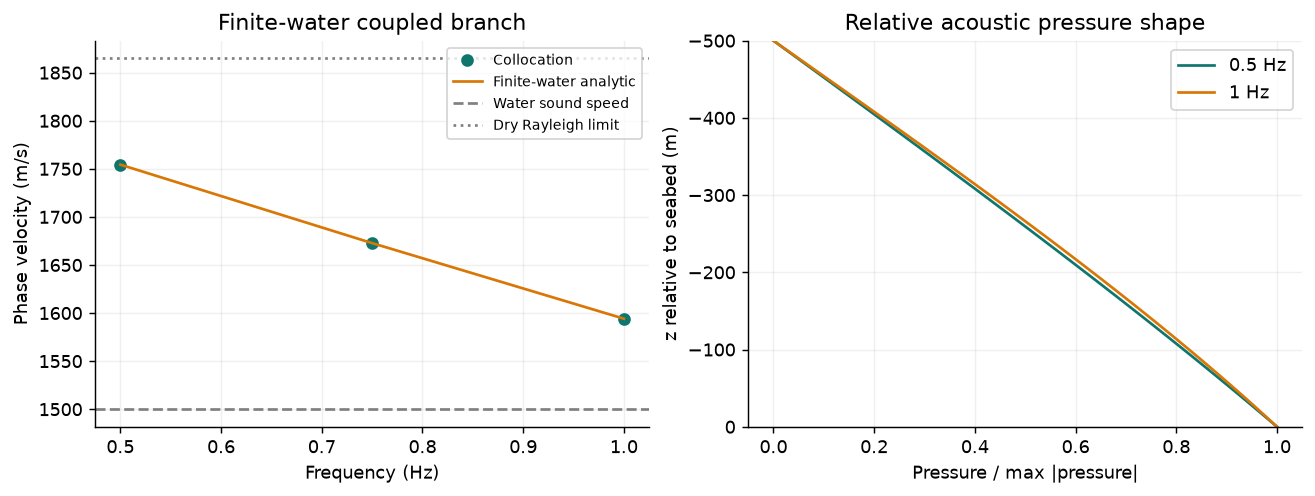

In [2]:
from gesc.analytic import rayleigh_velocity, scholte_velocity
from tutorials.scenarios import coastal

model, request = coastal()
model_table(model)
print("Water:", model.water.model_dump())
modes = solve_modes(model, request).fundamental()
f = np.array(request.frequencies_hz)
c = np.array([m.phase_velocity_m_s for m in modes])
exact = np.array([scholte_velocity(fi, model.halfspace, model.water) for fi in f])
analytic_error = float(np.max(np.abs(c / exact - 1)))
assert analytic_error < 1e-5
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
axes[0].plot(f, c, "o", label="Collocation")
axes[0].plot(f, exact, "-", label="Finite-water analytic")
axes[0].axhline(model.water.sound_speed_m_s, color="gray", ls="--", label="Water sound speed")
axes[0].axhline(
    rayleigh_velocity(model.halfspace), color="gray", ls=":", label="Dry Rayleigh limit"
)
axes[0].set(
    xlabel="Frequency (Hz)", ylabel="Phase velocity (m/s)", title="Finite-water coupled branch"
)
axes[0].legend(fontsize=8)
for mode in (modes[0], modes[-1]):
    pressure = np.array(mode.fluid_pressure_pa)
    axes[1].plot(
        pressure / np.max(np.abs(pressure)), mode.fluid_depth_m, label=f"{mode.frequency_hz:g} Hz"
    )
axes[1].set(
    xlabel="Pressure / max |pressure|",
    ylabel="z relative to seabed (m)",
    ylim=(0, -model.water.depth_m),
    title="Relative acoustic pressure shape",
)
axes[1].legend()
plt.show()

## 1. Separate solid and water sensitivity

The monitoring model is $d=G a+H b+\epsilon$, where $a=\Delta\ln V_s$ and $b$ contains changes in water depth, sound speed, and density. Water height here is the **external acoustic column**, not saturation or pore pressure within the sediment. These require different physical models.


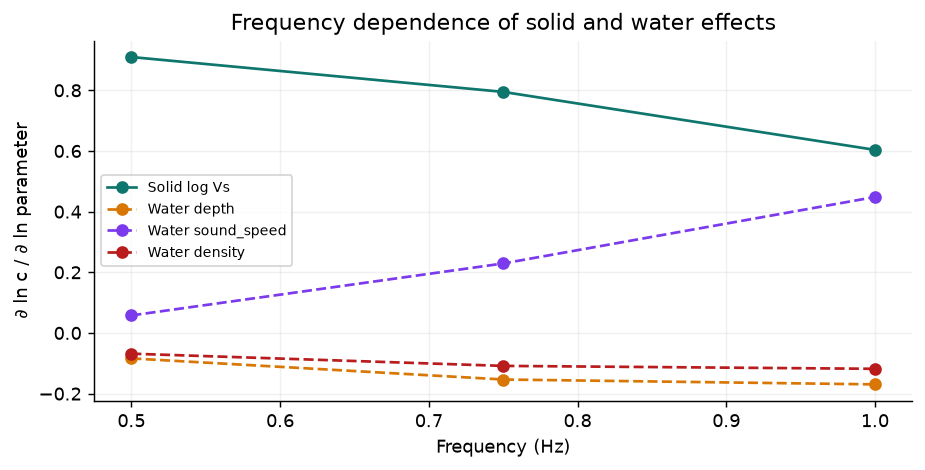

In [3]:
observation = phase_observation(request)
operator = linearize_phase(model, request, observation)
G, H = np.array(operator.g), np.array(operator.h)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(f, G[:, 0], "o-", label="Solid log Vs")
for j, name in enumerate(operator.nuisance_names):
    ax.plot(f, H[:, j], "o--", label=name.replace("log_water_", "Water "))
ax.set(
    xlabel="Frequency (Hz)",
    ylabel="∂ ln c / ∂ ln parameter",
    title="Frequency dependence of solid and water effects",
)
ax.legend(fontsize=8)
plt.show()
# A 1 m level rise over 500 m, without a solid change.
water_truth = np.array([np.log(501 / 500), 0, 0])
changed = solve_modes(perturb_model(model, [0.0], water_truth), request).fundamental()
data = np.array([m.phase_velocity_m_s for m in changed]) / c - 1
linear_error = float(np.max(np.abs(data - operator.predict([0.0], water_truth))))
assert linear_error < 0.25 * 3e-4

## 2. Marginalize the water uncertainty

Use $C_{\rm eff}=C_d+H C_bH^T$. Treating a water parameter as known is a strong prior choice. Compare a very tight water prior with a broader one: the marginal solid posterior should express the tradeoff rather than force all changing dispersion into Vs.

Both priors are zero-mean priors on **time changes**, not uncertainty in absolute bathymetry. Baseline-model uncertainty is not marginalized by this release.


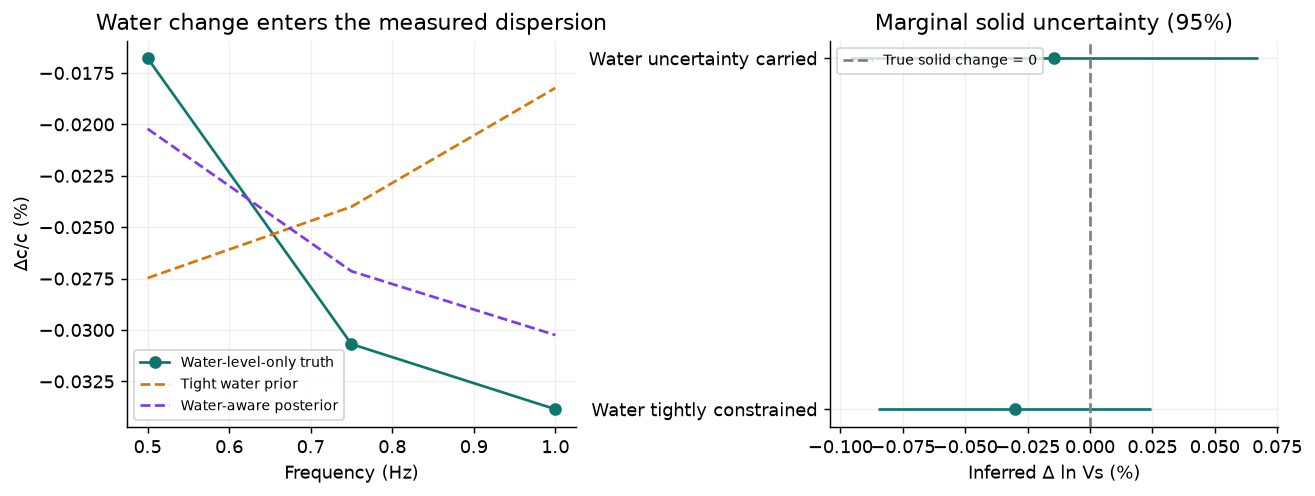

Conditional mean water log changes: (0.0006957253835688766, -0.00021518323113363155, 1.2103154018618283e-05)


In [4]:
Cd = correlated_covariance(len(f), sigma=3e-4, correlation=0.4)
Ca = ((0.003**2,),)


def invert_water(water_sd):
    return infer_time_lapse(
        operator,
        LinearInverseRequest(
            data_fractional=tuple(data),
            data_covariance=tuple(map(tuple, Cd)),
            prior_mean=(0.0,),
            prior_covariance=Ca,
            nuisance_prior_covariance=tuple(map(tuple, np.diag(np.array(water_sd) ** 2))),
        ),
    )


tight = invert_water((1e-6, 1e-6, 1e-6))
water_aware = invert_water((0.003, 0.001, 0.0005))
solid_sd = np.sqrt([tight.covariance_log_vs[0][0], water_aware.covariance_log_vs[0][0]])
assert solid_sd[1] >= solid_sd[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
axes[0].plot(f, data * 100, "o-", label="Water-level-only truth")
axes[0].plot(f, np.array(tight.predicted_fractional) * 100, "--", label="Tight water prior")
axes[0].plot(
    f, np.array(water_aware.predicted_fractional) * 100, "--", label="Water-aware posterior"
)
axes[0].set(
    xlabel="Frequency (Hz)", ylabel="Δc/c (%)", title="Water change enters the measured dispersion"
)
axes[0].legend(fontsize=8)
means = np.array([tight.mean_log_vs[0], water_aware.mean_log_vs[0]])
axes[1].errorbar(means * 100, [0, 1], xerr=1.96 * solid_sd * 100, fmt="o")
axes[1].axvline(0, color="gray", ls="--", label="True solid change = 0")
axes[1].set(
    yticks=[0, 1],
    yticklabels=["Water tightly constrained", "Water uncertainty carried"],
    xlabel="Inferred Δ ln Vs (%)",
    title="Marginal solid uncertainty (95%)",
)
axes[1].legend(fontsize=8)
plt.show()
print("Conditional mean water log changes:", water_aware.nuisance_mean)

## What belongs in an offshore monitoring analysis?

Acquire or model tide, bathymetry, temperature/salinity, and their uncertainties on the relevant time scale. Verify the fluid–solid branch before interpreting dispersion. A conditional water posterior is not an independent water-level measurement. Seafloor saturation, moving interfaces, attenuation, and a complex seabed require additional parameters or physics.

**Try:** replace the water-level perturbation with a sound-speed change, or tighten only the tide prior. For a layered seabed and DAS sensing geometry, continue to the Cook Inlet tutorial.


In [5]:
emit_metrics(
    {
        "case": "synthetic finite-water Scholte benchmark",
        "frequencies_hz": list(f),
        "max_analytic_relative_error": analytic_error,
        "max_linearization_discrepancy": linear_error,
        "solid_sd_tight_water": float(solid_sd[0]),
        "solid_sd_water_aware": float(solid_sd[1]),
        "checks_passed": True,
    }
)

{
  "case": "synthetic finite-water Scholte benchmark",
  "frequencies_hz": [
    0.5,
    0.75,
    1.0
  ],
  "max_analytic_relative_error": 3.058033826164319e-09,
  "max_linearization_discrepancy": 2.7272748366098535e-07,
  "solid_sd_tight_water": 0.00027904268269903767,
  "solid_sd_water_aware": 0.00041678542089069293,
  "checks_passed": true
}

case,synthetic finite-water Scholte benchmark
frequencies hz,"[0.5, 0.75, 1.0]"
max analytic relative error,3.058033826164319e-09
max linearization discrepancy,2.7272748366098535e-07
solid sd tight water,0.00027904268269903767
solid sd water aware,0.00041678542089069293
checks passed,True
